In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)

# Treat impossible zeros as missing values
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = \
    df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)

X, y = df.drop(columns="Outcome"), df["Outcome"]

# 60/20/20 Train / Val / Test Split
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (460, 8) | Val: (154, 8) | Test: (154, 8)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Define models
baseline = DummyClassifier(strategy="most_frequent")
logreg = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("scaler", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=1000, random_state=42))])
rf = Pipeline([("imputer", SimpleImputer(strategy="median")),
               ("clf", RandomForestClassifier(n_estimators=300, random_state=42))])

# Train on training set only
baseline.fit(X_train, y_train)
logreg.fit(X_train, y_train)
rf.fit(X_train, y_train)

# Evaluate on Validation set
from sklearn.metrics import f1_score, recall_score
print("=== Validation Performance (for threshold/model selection) ===")
for name, model in [("LogReg", logreg), ("RF", rf)]:
    probs = model.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.40).astype(int)
    print(f"{name} @ thr=0.40: Recall={recall_score(y_val, preds):.3f} F1={f1_score(y_val, preds):.3f}")

=== Validation Performance (for threshold/model selection) ===
LogReg @ thr=0.40: Recall=0.667 F1=0.673
RF @ thr=0.40: Recall=0.741 F1=0.702


In [3]:
from sklearn.metrics import (accuracy_score, precision_score, confusion_matrix,
                             roc_auc_score, brier_score_loss)

print("=== FINAL TEST EVALUATION (LogReg @ thr=0.40) ===")
# We deploy LogReg
test_probs = logreg.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.40).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()

print(f"Accuracy : {accuracy_score(y_test, test_preds):.3f}")
print(f"Precision: {precision_score(y_test, test_preds, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, test_preds):.3f}")
print(f"F1 Score : {f1_score(y_test, test_preds):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, test_probs):.3f}")
print(f"Brier    : {brier_score_loss(y_test, test_probs):.3f}")
print(f"Confusion: TN={tn} FP={fp} FN={fn} TP={tp}")

# Age-Group Analysis (Requested by judge)
print("\n=== Age-Group Performance (Test Set) ===")
test_ages = X_test['Age'].values
for lo, hi in [(21, 30), (30, 40), (40, 50), (50, 100)]:
    mask = (test_ages >= lo) & (test_ages < hi)
    if mask.sum() > 0:
        rec = recall_score(y_test[mask], test_preds[mask], zero_division=0)
        print(f"Age {lo}-{hi}: n={mask.sum()}, Recall={rec:.3f}")

=== FINAL TEST EVALUATION (LogReg @ thr=0.40) ===
Accuracy : 0.721
Precision: 0.604
Recall   : 0.593
F1 Score : 0.598
ROC-AUC  : 0.817
Brier    : 0.175
Confusion: TN=79 FP=21 FN=22 TP=32

=== Age-Group Performance (Test Set) ===
Age 21-30: n=85, Recall=0.438
Age 30-40: n=30, Recall=0.600
Age 40-50: n=24, Recall=0.833
Age 50-100: n=15, Recall=0.500


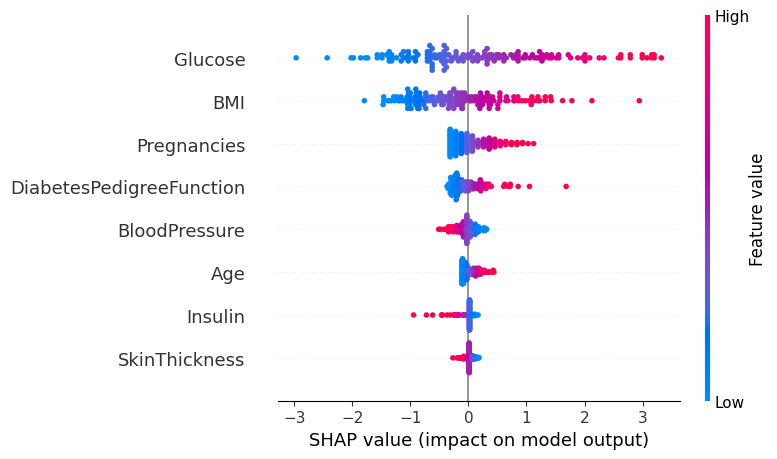

In [4]:
import shap
import matplotlib.pyplot as plt

# Prepare scaled data for SHAP
imputer = logreg.named_steps["imputer"]
scaler = logreg.named_steps["scaler"]
clf = logreg.named_steps["clf"]

X_test_imp = imputer.transform(X_test)
X_test_scaled = scaler.transform(X_test_imp)

# Background dataset (just a small sample of training data)
X_train_imp = imputer.transform(X_train)
X_train_scaled = scaler.transform(X_train_imp)
background = X_train_scaled[:100]

explainer = shap.LinearExplainer(clf, background)
shap_values = explainer.shap_values(X_test_scaled)

# Plot global feature importance
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns, show=True)

In [5]:
import joblib
from google.colab import files

# Retrain on Train + Val (everything except Test)
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
]).fit(X_trainval, y_trainval)

joblib.dump(final_model, "healthsignal_final.pkl")
print("Saved healthsignal_final.pkl")
files.download("healthsignal_final.pkl")

Saved healthsignal_final.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>